<a href="https://colab.research.google.com/github/lalitha-630/ai-soc/blob/main/Training_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Loading dataset...

Total rows in the combined dataset: 257,673
Total features: 45

--- Performing Stratified 80/20 Split...
New Train split size: 206,138 (80.0%)
New Test split size: 51,535 (20.0%)

--- Balancing Training Set...
Balanced Train - Label 0 (Normal): 74,400
Balanced Train - Label 1 (Attack): 74,400
Total Balanced Train Rows: 148,800

--- Generating Plots...


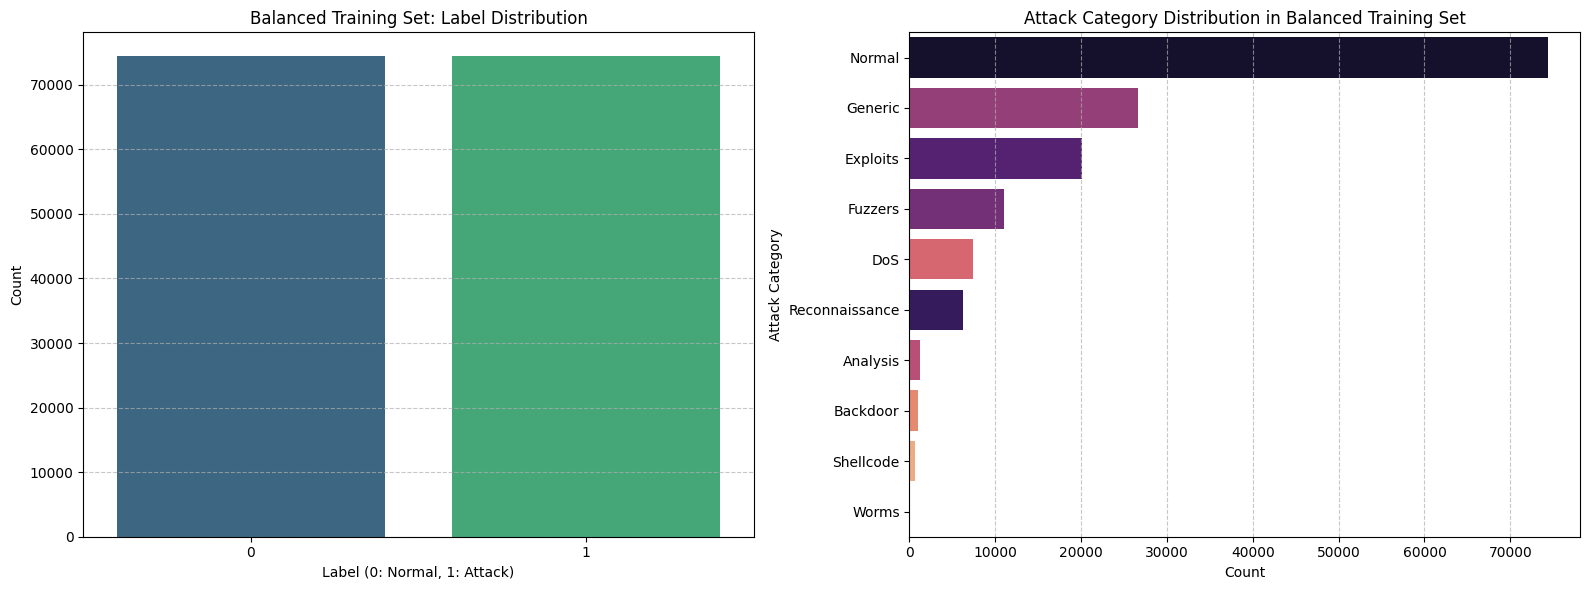

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# 1. Load the dataset from Hugging Face
print("--- Loading dataset...")
ds = load_dataset("Mireu-Lab/UNSW-NB15")

# Convert splits to Pandas DataFrames
train_orig = ds['train'].to_pandas()
test_orig = ds['test'].to_pandas()

# Combine to handle full dataset split restructuring
combined_df = pd.concat([train_orig, test_orig], ignore_index=True)

# 2. Display basic info
print(f"\nTotal rows in the combined dataset: {len(combined_df):,}")
print(f"Total features: {len(combined_df.columns)}")

# 3. Restructure train/test split (80-20 Stratified)
print("\n--- Performing Stratified 80/20 Split...")
if 'split' in combined_df.columns:
    df_clean = combined_df.drop(columns=['split'])
else:
    df_clean = combined_df.copy()

train_df_new, test_df_new = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=42,
    stratify=df_clean['label']
)

print(f"New Train split size: {len(train_df_new):,} ({len(train_df_new)/len(df_clean)*100:.1f}%)")
print(f"New Test split size: {len(test_df_new):,} ({len(test_df_new)/len(df_clean)*100:.1f}%)")

# 4. Balance the labeled training data (Downsampling the majority class)
print("\n--- Balancing Training Set...")
train_0 = train_df_new[train_df_new['label'] == 0]
train_1 = train_df_new[train_df_new['label'] == 1]

min_class_size = min(len(train_0), len(train_1))

train_0_balanced = train_0.sample(n=min_class_size, random_state=42)
train_1_balanced = train_1.sample(n=min_class_size, random_state=42)

train_df_balanced = pd.concat([train_0_balanced, train_1_balanced], ignore_index=True)
train_df_balanced = train_df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Balanced Train - Label 0 (Normal): {len(train_df_balanced[train_df_balanced['label'] == 0]):,}")
print(f"Balanced Train - Label 1 (Attack): {len(train_df_balanced[train_df_balanced['label'] == 1]):,}")
print(f"Total Balanced Train Rows: {len(train_df_balanced):,}")

# 5. Visualizations
print("\n--- Generating Plots...")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Balanced Training Target Class Distribution
sns.countplot(data=train_df_balanced, x='label', ax=axes[0], palette='viridis', hue='label', legend=False)
axes[0].set_title('Balanced Training Set: Label Distribution')
axes[0].set_xlabel('Label (0: Normal, 1: Attack)')
axes[0].set_ylabel('Count')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Attack Categories in the Balanced Training Dataset
sns.countplot(
    data=train_df_balanced,
    y='attack_cat',
    ax=axes[1],
    order=train_df_balanced['attack_cat'].value_counts().index,
    palette='magma',
    hue='attack_cat',
    legend=False
)
axes[1].set_title('Attack Category Distribution in Balanced Training Set')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Attack Category')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [5]:
# Display information about all features in the dataset
pd.set_option('display.max_columns', None)
print(f"Total features: {len(combined_df.columns)}")
print("\nFeature list and data types:")
print(combined_df.info(verbose=True, show_counts=True))

Total features: 46

Feature list and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257673 entries, 0 to 257672
Data columns (total 46 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  object 
 3   service            257673 non-null  object 
 4   state              257673 non-null  object 
 5   spkts              257673 non-null  int64  
 6   dpkts              257673 non-null  int64  
 7   sbytes             257673 non-null  int64  
 8   dbytes             257673 non-null  int64  
 9   rate               257673 non-null  float64
 10  sttl               257673 non-null  int64  
 11  dttl               257673 non-null  int64  
 12  sload              257673 non-null  float64
 13  dload              257673 non-null  float64
 14  sloss              257673 non-null  int64  
 15  dl

In [10]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder

# 1. Prepare and preprocess datasets
print("--- Preprocessing Data...")

# Define target and features to drop
target_col = 'label'
drop_cols = ['id', 'attack_cat', 'split', 'label']

# Copy datasets
train_prep = train_df_balanced.copy()
test_prep = test_df_new.copy()

# Separate features and target
y_train = train_prep[target_col]
y_test = test_prep[target_col]

X_train = train_prep.drop(columns=[col for col in drop_cols if col in train_prep.columns])
X_test = test_prep.drop(columns=[col for col in drop_cols if col in test_prep.columns])

# Identify categorical columns
cat_cols = ['proto', 'service', 'state']

# Fit LabelEncoders on the training split and transform both splits
for col in cat_cols:
    if col in X_train.columns:
        le = LabelEncoder()
        # Fit on training data
        X_train[col] = le.fit_transform(X_train[col].astype(str))

        # Handle unseen values in test split securely by mapping them to an 'unknown' class placeholder if necessary
        # Create a mapping dictionary
        le_dict = dict(zip(le.classes_, le.transform(le.classes_)))
        X_test[col] = X_test[col].astype(str).map(le_dict).fillna(-1).astype(int)

print(f"Final feature count for training: {X_train.shape[1]}")

--- Preprocessing Data...
Final feature count for training: 42


In [14]:
# 2. Train the Random Forest Model
print("--- Training Random Forest Classifier (Optimized with n_jobs=-1)...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Model training complete!")

# 3. Save the model to model.pkl
joblib.dump(rf_model, 'model.pkl')
print("Saved trained model to 'model.pkl'")

--- Training Random Forest Classifier (Optimized with n_jobs=-1)...
Model training complete!
Saved trained model to 'model.pkl'


In [12]:
# 4. Test the model and generate metrics
print("--- Testing and Evaluation...")
y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='binary')
recall = recall_score(y_test, y_pred, average='binary')
f1 = f1_score(y_test, y_pred, average='binary')

print("\n================ EVALUATION METRICS ================")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print("====================================================")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Attack (1)']))

--- Testing and Evaluation...

================ EVALUATION METRICS ================
Accuracy:  0.9475
Precision: 0.9787
Recall:    0.9382
F1 Score:  0.9581

Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.90      0.96      0.93     18600
  Attack (1)       0.98      0.94      0.96     32935

    accuracy                           0.95     51535
   macro avg       0.94      0.95      0.94     51535
weighted avg       0.95      0.95      0.95     51535



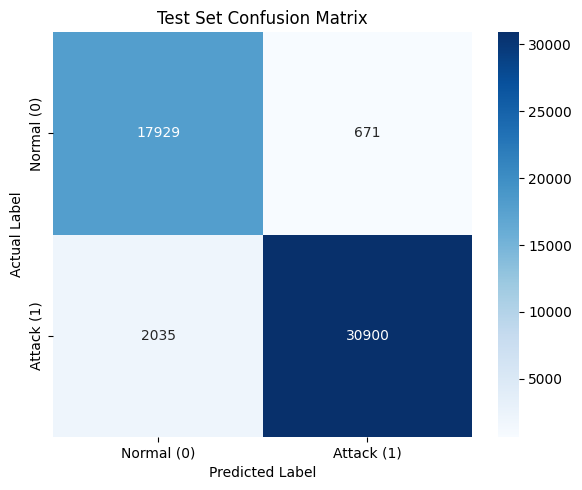

In [13]:
# 5. Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal (0)', 'Attack (1)'], yticklabels=['Normal (0)', 'Attack (1)'])
plt.title('Test Set Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()